# CNN-LSTM V2 قوی‌تر و کنترل‌شده برای پیش‌بینی PM10 در افق 24 ساعت

این نوت‌بوک نسخه‌ی **24h-only** همان مدل موفق `CNN-LSTM V2` است.  
**معماری شبکه، تعداد لایه‌ها، تعداد فیلترها/واحدها، مسیر Residual، تابع زیان، Optimizer، نرخ یادگیری، Dropout، Batch Size، EarlyStopping و سایر تنظیمات آموزش نسبت به نوت‌بوک اصلی تغییر نکرده‌اند.**

تنها تغییر آزمایشی این نسخه:
- اجرای افق‌های 1h و 72h حذف شده است.
- فقط مسئله‌ی زیر اجرا می‌شود:

\[
(X_{t-23},\ldots,X_t)\rightarrow PM10_{t+24}
\]

پس از ارزیابی، مجموعه نمودارهای تشخیصی و مقایسه‌ای مطابق گایدلاین مصورسازی فصل نتایج تولید می‌شوند؛ همه‌ی نمودارها هم **داخل نوت‌بوک نمایش داده می‌شوند** و هم با کیفیت `300 dpi` در پوشه‌ی `results_figures/` ذخیره می‌شوند.


## 1. نصب کتابخانه‌ها

اگر TensorFlow یا سایر کتابخانه‌ها در محیط شما نصب نیستند، خط زیر را یک بار اجرا کنید.


In [1]:
# Optional installation (uncomment if needed)
!pip install -q tensorflow scikit-learn pandas matplotlib seaborn joblib

## 2. کتابخانه‌ها و تنظیمات بازتولیدپذیری

In [2]:
import os
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Conv1D, LSTM, Dense, Dropout,
    Concatenate, Add, LayerNormalization,
    Activation, SpatialDropout1D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ---------------------------
# Experiment configuration
# ---------------------------
DATA_PATH = Path("Gucheng.csv")
TARGET = "PM10"

LOOKBACK = 24
HORIZONS = [24]

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Same training protocol as RNN/LSTM/GRU notebooks
EPOCHS = 100
BATCH_SIZE = 64
LEARNING_RATE = 4e-4
DROPOUT = 0.20
PATIENCE = 10

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

print("TensorFlow:", tf.__version__)
print("Data path:", DATA_PATH.resolve())
print("LOOKBACK:", LOOKBACK)
print("HORIZONS:", HORIZONS)

TensorFlow: 2.20.0
Data path: /content/Gucheng.csv
LOOKBACK: 24
HORIZONS: [24]


In [4]:
from google.colab import files
uploaded = files.upload()

Saving Gucheng.csv to Gucheng.csv



## 3. بارگذاری داده و ساخت محور زمانی

این مرحله همان pipeline نوت‌بوک‌های RNN/LSTM/GRU است.


In [5]:
df_raw = pd.read_csv(DATA_PATH)

required_columns = [
    "year", "month", "day", "hour",
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"
]

missing_required = [c for c in required_columns if c not in df_raw.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

df = df_raw.copy()
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("datetime").reset_index(drop=True)

print("Shape:", df.shape)
print("Time range:", df["datetime"].min(), "to", df["datetime"].max())
display(df.head())

Shape: (35064, 19)
Time range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,6.0,18.0,5.0,NaN,800.0,88.0,0.1,1021.1,-18.6,0.0,NW,4.4,Gucheng,2013-03-01 00:00:00
1,2,2013,3,1,1,6.0,15.0,5.0,NaN,800.0,88.0,-0.3,1021.5,-19.0,0.0,NW,4.0,Gucheng,2013-03-01 01:00:00
2,3,2013,3,1,2,5.0,18.0,NaN,NaN,700.0,52.0,-0.7,1021.5,-19.8,0.0,WNW,4.6,Gucheng,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,20.0,6.0,NaN,NaN,NaN,-1.0,1022.7,-21.2,0.0,W,2.8,Gucheng,2013-03-01 03:00:00
4,5,2013,3,1,4,5.0,17.0,5.0,NaN,600.0,73.0,-1.3,1023.0,-21.4,0.0,WNW,3.6,Gucheng,2013-03-01 04:00:00


## 4. کنترل کیفیت اولیه سری زمانی

In [6]:
duplicate_times = df["datetime"].duplicated().sum()
time_diffs = df["datetime"].diff().dropna()
irregular_steps = (time_diffs != pd.Timedelta(hours=1)).sum()

print("Duplicate timestamps:", duplicate_times)
print("Irregular (non-hourly) time steps:", irregular_steps)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(3)
}).sort_values("missing_percent", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0])

if duplicate_times > 0:
    raise ValueError("Duplicate timestamps detected. Resolve them before modeling.")
if irregular_steps > 0:
    print("WARNING: The time series is not perfectly hourly.")

Duplicate timestamps: 0
Irregular (non-hourly) time steps: 0


,missing_count,missing_percent
CO,1401,3.996
O3,729,2.079
NO2,668,1.905
PM2.5,646,1.842
SO2,507,1.446
PM10,381,1.087
wd,159,0.453
DEWP,51,0.145
TEMP,51,0.145
PRES,50,0.143


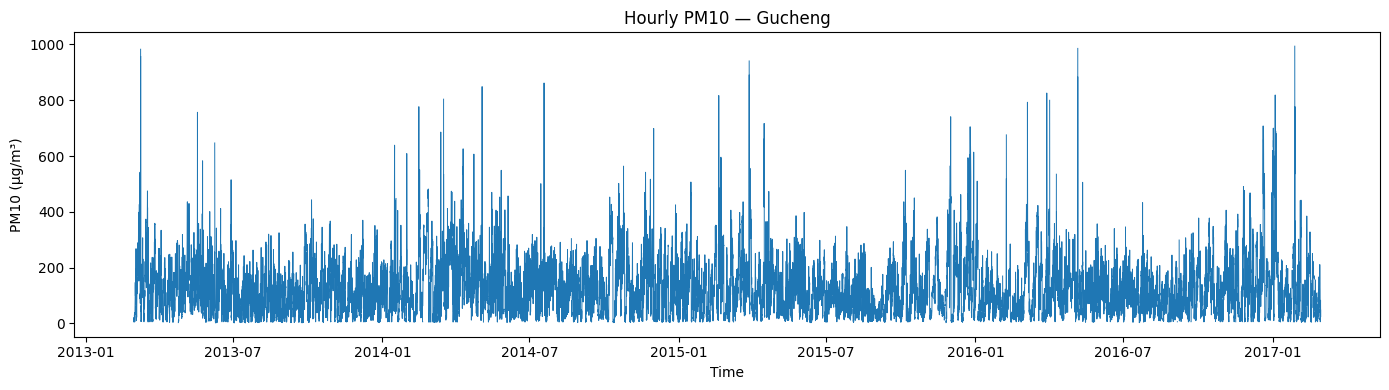

In [7]:
plt.figure(figsize=(14, 4))
plt.plot(df["datetime"], df["PM10"], linewidth=0.7)
plt.title("Hourly PM10 — Gucheng")
plt.xlabel("Time")
plt.ylabel("PM10 (µg/m³)")
plt.tight_layout()
plt.show()


## 5. تقسیم زمانی Train / Validation / Test

داده‌ها بدون Shuffle و به‌صورت زمانی تقسیم می‌شوند.


In [8]:
n = len(df)
train_end = int(n * TRAIN_RATIO)
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

print("Total rows:", n)
print("Train rows:", train_end)
print("Validation rows:", val_end - train_end)
print("Test rows:", n - val_end)

print("\nTrain:", df.loc[0, "datetime"], "→", df.loc[train_end - 1, "datetime"])
print("Validation:", df.loc[train_end, "datetime"], "→", df.loc[val_end - 1, "datetime"])
print("Test:", df.loc[val_end, "datetime"], "→", df.loc[n - 1, "datetime"])

Total rows: 35064
Train rows: 24544
Validation rows: 5260
Test rows: 5260

Train: 2013-03-01 00:00:00 → 2015-12-18 15:00:00
Validation: 2015-12-18 16:00:00 → 2016-07-24 19:00:00
Test: 2016-07-24 20:00:00 → 2017-02-28 23:00:00



## 6. مدیریت مقادیر گمشده بدون نشت اطلاعات

همان روش قبلی:

1. Forward Fill
2. Median فقط از Train برای متغیرهای عددی باقی‌مانده
3. Mode فقط از Train برای جهت باد

هیچ داده آینده‌ای برای پر کردن گذشته استفاده نمی‌شود.


In [9]:
numeric_measure_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

train_medians = df.loc[:train_end - 1, numeric_measure_cols].median()
train_wd_mode = df.loc[:train_end - 1, "wd"].mode(dropna=True)
train_wd_mode = train_wd_mode.iloc[0] if len(train_wd_mode) else "N"

# Causal imputation
df[numeric_measure_cols] = df[numeric_measure_cols].ffill()
df["wd"] = df["wd"].ffill()

# Remaining values at the beginning
df[numeric_measure_cols] = df[numeric_measure_cols].fillna(train_medians)
df["wd"] = df["wd"].fillna(train_wd_mode)

print(
    "Remaining missing values in modeling columns:",
    int(df[numeric_measure_cols + ["wd"]].isna().sum().sum())
)

Remaining missing values in modeling columns: 0


## 7. مهندسی ویژگی‌های زمانی و جهت باد

In [10]:
# Calendar features
df["dow"] = df["datetime"].dt.dayofweek

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12)

df["dow_sin"] = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["dow"] / 7)

# 16-point compass → degrees
wind_degrees = {
    "N": 0.0, "NNE": 22.5, "NE": 45.0, "ENE": 67.5,
    "E": 90.0, "ESE": 112.5, "SE": 135.0, "SSE": 157.5,
    "S": 180.0, "SSW": 202.5, "SW": 225.0, "WSW": 247.5,
    "W": 270.0, "WNW": 292.5, "NW": 315.0, "NNW": 337.5
}

unknown_wd = sorted(set(df["wd"].dropna().unique()) - set(wind_degrees))
if unknown_wd:
    raise ValueError(f"Unknown wind-direction categories: {unknown_wd}")

wd_rad = np.deg2rad(df["wd"].map(wind_degrees).astype(float))
df["wd_sin"] = np.sin(wd_rad)
df["wd_cos"] = np.cos(wd_rad)

display(df[[
    "datetime",
    "hour_sin", "hour_cos",
    "month_sin", "month_cos",
    "dow_sin", "dow_cos",
    "wd", "wd_sin", "wd_cos"
]].head())

,datetime,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,wd,wd_sin,wd_cos
0,2013-03-01 00:00:00,0.000000,1.000000,0.866025,0.5,-0.433884,-0.900969,NW,-0.707107,7.071068e-01
1,2013-03-01 01:00:00,0.258819,0.965926,0.866025,0.5,-0.433884,-0.900969,NW,-0.707107,7.071068e-01
2,2013-03-01 02:00:00,0.500000,0.866025,0.866025,0.5,-0.433884,-0.900969,WNW,-0.923880,3.826834e-01
3,2013-03-01 03:00:00,0.707107,0.707107,0.866025,0.5,-0.433884,-0.900969,W,-1.000000,-1.836970e-16
4,2013-03-01 04:00:00,0.866025,0.500000,0.866025,0.5,-0.433884,-0.900969,WNW,-0.923880,3.826834e-01


## 8. مجموعه 19 ویژگی ورودی

In [11]:
FEATURES = [
    # Pollutants
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    # Meteorology
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
    # Cyclical calendar features
    "hour_sin", "hour_cos",
    "month_sin", "month_cos",
    "dow_sin", "dow_cos",
    # Wind direction
    "wd_sin", "wd_cos"
]

print("Number of input features:", len(FEATURES))
print(FEATURES)

assert len(FEATURES) == 19

display(df[FEATURES + [TARGET]].describe().T)

Number of input features: 19
['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'wd_sin', 'wd_cos']


,count,mean,std,min,25%,50%,75%,max
PM2.5,35064.0,8.434520e+01,83.228885,2.000000,24.000000,6.000000e+01,116.000000,770.000000
PM10,35064.0,1.193290e+02,97.650791,2.000000,45.000000,1.000000e+02,167.000000,994.000000
SO2,35064.0,1.602008e+01,27.031552,0.285600,2.000000,7.000000e+00,20.000000,500.000000
NO2,35064.0,5.582096e+01,36.525063,2.000000,26.000000,5.000000e+01,79.000000,276.000000
CO,35064.0,1.352702e+03,1236.264470,100.000000,600.000000,9.000000e+02,1700.000000,10000.000000
O3,35064.0,5.870256e+01,58.243262,0.214200,10.000000,4.500000e+01,84.000000,450.000000
TEMP,35064.0,1.385569e+01,11.295553,-15.600000,3.600000,1.480000e+01,23.500000,41.600000
PRES,35064.0,1.008836e+03,10.104802,984.000000,1000.500000,1.008500e+03,1017.000000,1038.100000
DEWP,35064.0,2.600456e+00,13.789758,-34.600000,-9.000000,3.000000e+00,15.300000,27.400000
RAIN,35064.0,6.437372e-02,0.838142,0.000000,0.000000,0.000000e+00,0.000000,41.900000



## 9. Standardization فقط بر اساس Train

دقیقاً مثل مدل‌های عمیق قبلی:

\[
z=\frac{x-\mu_{\mathrm{train}}}{\sigma_{\mathrm{train}}}
\]

Scalers فقط روی Train برازش می‌شوند و سپس روی Validation و Test اعمال می‌شوند.


In [12]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

feature_scaler.fit(df.loc[:train_end - 1, FEATURES])
target_scaler.fit(df.loc[:train_end - 1, [TARGET]])

X_all_scaled = feature_scaler.transform(df[FEATURES]).astype(np.float32)
y_all_scaled = target_scaler.transform(df[[TARGET]]).astype(np.float32).reshape(-1)

print("Scaled feature matrix:", X_all_scaled.shape)
print("Scaled target vector:", y_all_scaled.shape)

Scaled feature matrix: (35064, 19)
Scaled target vector: (35064,)


## 10. ساخت Sliding Windows برای افق 24 ساعت

در این نسخه فقط افق 24 ساعت اجرا می‌شود. اگر آخرین ساعت پنجره‌ی ورودی را \(t\) در نظر بگیریم:

\[
X=[X_{t-23},\ldots,X_t]
\]

و هدف:

\[
y=PM10_{t+24}
\]

است. تابع ساخت پنجره همان تابع نوت‌بوک اصلی است و تغییری در منطق نمونه‌سازی زمانی داده نشده است.

In [13]:
def create_forecasting_windows(X, y, datetimes, lookback=24, horizon=1):
    X_seq, y_seq, target_indices, target_times = [], [], [], []

    first_target = lookback + horizon - 1

    for target_idx in range(first_target, len(X)):
        input_end = target_idx - horizon + 1  # exclusive
        input_start = input_end - lookback

        X_seq.append(X[input_start:input_end])
        y_seq.append(y[target_idx])
        target_indices.append(target_idx)
        target_times.append(datetimes.iloc[target_idx])

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(target_indices, dtype=np.int64),
        pd.DatetimeIndex(target_times)
    )


def prepare_horizon_data(horizon):
    X_seq, y_seq, target_indices, target_times = create_forecasting_windows(
        X_all_scaled,
        y_all_scaled,
        df["datetime"],
        lookback=LOOKBACK,
        horizon=horizon
    )

    train_mask = target_indices < train_end
    val_mask = (target_indices >= train_end) & (target_indices < val_end)
    test_mask = target_indices >= val_end

    X_train, y_train = X_seq[train_mask], y_seq[train_mask]
    X_val, y_val = X_seq[val_mask], y_seq[val_mask]
    X_test, y_test = X_seq[test_mask], y_seq[test_mask]

    time_train = target_times[train_mask]
    time_val = target_times[val_mask]
    time_test = target_times[test_mask]

    assert X_train.shape[1:] == (LOOKBACK, len(FEATURES))
    assert X_val.shape[1:] == (LOOKBACK, len(FEATURES))
    assert X_test.shape[1:] == (LOOKBACK, len(FEATURES))

    return {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "target_indices": target_indices,
        "test_target_indices": target_indices[test_mask],
        "time_train": time_train,
        "time_val": time_val,
        "time_test": time_test
    }

### کنترل شکل ورودی افق 24 ساعت

In [14]:
for h in HORIZONS:
    d = prepare_horizon_data(h)
    print(f"\nHorizon = {h}h")
    print("X_train:", d["X_train"].shape)
    print("X_val:  ", d["X_val"].shape)
    print("X_test: ", d["X_test"].shape)
    print("Expected input shape: (samples, 24, 19)")


Horizon = 24h
X_train: (24497, 24, 19)
X_val:   (5260, 24, 19)
X_test:  (5260, 24, 19)
Expected input shape: (samples, 24, 19)



## 11. Persistence Baseline

همان baseline آزمایش‌های قبل:

\[
\hat{PM10}_{t+h}=PM10_t
\]

برای هر سه افق به‌صورت جداگانه محاسبه می‌شود.


In [15]:
pm10_feature_idx = FEATURES.index("PM10")

pm10_mean_feature = feature_scaler.mean_[pm10_feature_idx]
pm10_scale_feature = feature_scaler.scale_[pm10_feature_idx]


def persistence_from_windows(X_test):
    last_scaled_pm10 = X_test[:, -1, pm10_feature_idx]
    return (
        last_scaled_pm10 * pm10_scale_feature
        + pm10_mean_feature
    )


## 12. معماری CNN-LSTM V2: Multi-Scale Residual CNN + Stacked LSTM

نسخه V2 سه ضعف اصلی نسخه قبلی را هدف می‌گیرد:

### 1. استخراج ویژگی فقط در یک مقیاس
نسخه قبل تقریباً فقط با kernel=3 کار می‌کرد. در این نسخه دو شاخه CNN موازی داریم:

- شاخه اول: `kernel_size=3`
- شاخه دوم: `kernel_size=5`

بنابراین شبکه می‌تواند هم الگوهای خیلی کوتاه و هم الگوهای محلی کمی گسترده‌تر را هم‌زمان استخراج کند.

### 2. احتمال از دست رفتن اطلاعات خام مفید
خروجی دو شاخه CNN با یک `1×1 Conv` به 64 کانال فشرده می‌شود و سپس یک **Residual / Skip Connection** از ورودی به آن اضافه می‌شود.

این مسیر کمکی باعث می‌شود CNN مجبور نباشد همه اطلاعات مفید را از صفر بازسازی کند.

### 3. ظرفیت زمانی کم نسخه قبلی
نسخه قبل فقط یک `LSTM(64)` داشت.

نسخه جدید از:

```text
LSTM(96, return_sequences=True)
        ↓
LSTM(64)
```

استفاده می‌کند.

این کار ظرفیت مدل‌سازی زمانی را به شکل محسوسی افزایش می‌دهد، ولی تعداد پارامترها همچنان در همان مرتبه‌ی LSTM پایه نگه داشته می‌شود.

### ساختار نهایی

```text
                    ┌─ Conv1D(64, k=3, causal) ─┐
Input (24,19) ──────┤                           ├─ Concatenate
                    └─ Conv1D(64, k=5, causal) ─┘
                                      ↓
                               Conv1D(64, k=1)
                                      ↓
Input ───── Conv1D(64, k=1) ─────────┤
                                      ↓
                                    Add
                                      ↓
                              LayerNormalization
                                      ↓
                                  ReLU
                                      ↓
                             SpatialDropout1D(0.2)
                                      ↓
                        LSTM(96, return_sequences=True)
                                      ↓
                                Dropout(0.2)
                                      ↓
                                  LSTM(64)
                                      ↓
                                Dropout(0.2)
                                      ↓
                                Dense(64)
                                      ↓
                                Dropout(0.2)
                                      ↓
                                Dense(32)
                                      ↓
                                 Dense(1)
                                      ↓
                                  PM10
```

### چرا MaxPooling نداریم؟
چون فقط 24 گام زمانی داریم و نمی‌خواهیم resolution زمانی به‌صورت مصنوعی کاهش پیدا کند.


In [16]:

def build_cnn_lstm_model(input_shape):
    """
    CNN-LSTM V2
    Multi-scale causal CNN + residual connection + stacked LSTM.

    Approximate parameter count:
    ~128.8K, intentionally kept close to the previous LSTM baseline
    (~138.7K) for a more capacity-comparable benchmark.
    """
    tf.keras.utils.set_random_seed(SEED)

    inputs = Input(shape=input_shape, name="input_24x19")

    # ---------------------------------------------------------
    # Multi-scale causal temporal feature extraction
    # ---------------------------------------------------------
    branch_k3 = Conv1D(
        filters=64,
        kernel_size=3,
        padding="causal",
        activation="relu",
        name="conv_k3"
    )(inputs)

    branch_k5 = Conv1D(
        filters=64,
        kernel_size=5,
        padding="causal",
        activation="relu",
        name="conv_k5"
    )(inputs)

    x = Concatenate(name="multiscale_concat")(
        [branch_k3, branch_k5]
    )

    # Fuse the two CNN branches back to 64 channels
    x = Conv1D(
        filters=64,
        kernel_size=1,
        padding="same",
        activation=None,
        name="multiscale_fusion_1x1"
    )(x)

    # ---------------------------------------------------------
    # Residual / skip pathway
    # Preserve direct information from the original input.
    # ---------------------------------------------------------
    skip = Conv1D(
        filters=64,
        kernel_size=1,
        padding="same",
        activation=None,
        name="input_projection_skip"
    )(inputs)

    x = Add(name="residual_add")([x, skip])
    x = LayerNormalization(name="cnn_layer_norm")(x)
    x = Activation("relu", name="cnn_relu")(x)

    # Drop entire temporal feature maps rather than isolated values
    x = SpatialDropout1D(
        DROPOUT,
        name="spatial_dropout"
    )(x)

    # ---------------------------------------------------------
    # Stronger temporal modeling
    # ---------------------------------------------------------
    x = LSTM(
        96,
        return_sequences=True,
        name="lstm_96"
    )(x)

    x = Dropout(
        DROPOUT,
        name="dropout_after_lstm96"
    )(x)

    x = LSTM(
        64,
        return_sequences=False,
        name="lstm_64"
    )(x)

    x = Dropout(
        DROPOUT,
        name="dropout_after_lstm64"
    )(x)

    # ---------------------------------------------------------
    # Regression head
    # ---------------------------------------------------------
    x = Dense(
        64,
        activation="relu",
        name="dense_64"
    )(x)

    x = Dropout(
        DROPOUT,
        name="dropout_dense"
    )(x)

    x = Dense(
        32,
        activation="relu",
        name="dense_32"
    )(x)

    outputs = Dense(
        1,
        name="pm10_output"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="CNN_LSTM_V2_PM10"
    )

    # IMPORTANT FOR FAIRNESS:
    # Same optimizer, learning rate and loss as RNN/LSTM/GRU.
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="mse",
        metrics=["mae"]
    )

    return model


input_shape = (LOOKBACK, len(FEATURES))
demo_model = build_cnn_lstm_model(input_shape)
demo_model.summary()

print("\nCNN-LSTM V2 parameters:", demo_model.count_params())

REFERENCE_LSTM_PARAMS = 138_689
difference_pct = (
    100.0
    * (demo_model.count_params() - REFERENCE_LSTM_PARAMS)
    / REFERENCE_LSTM_PARAMS
)

print("Reference LSTM parameters:", REFERENCE_LSTM_PARAMS)
print(
    "Difference vs reference LSTM:",
    f"{difference_pct:+.2f}%"
)


Model: "CNN_LSTM_V2_PM10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_24x19         │ (None, 24, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k3 (Conv1D)    │ (None, 24, 64)    │      3,712 │ input_24x19[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_k5 (Conv1D)    │ (None, 24, 64)    │      6,144 │ input_24x19[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiscale_concat   │ (None, 24, 128)   │          0 │ conv_k3[0][0],    │
│ (Concatenate)       │                   │            │ conv_k5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiscale_fusion_… │ (None, 24, 64)    │      8,256 │ multiscale_conca… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection_s… │ (None, 24, 64)    │      1,280 │ input_24x19[0][0] │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_add (Add)  │ (None, 24, 64)    │          0 │ multiscale_fusio… │
│                     │                   │            │ input_projection… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_layer_norm      │ (None, 24, 64)    │        128 │ residual_add[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_relu            │ (None, 24, 64)    │          0 │ cnn_layer_norm[0… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout     │ (None, 24, 64)    │          0 │ cnn_relu[0][0]    │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_96 (LSTM)      │ (None, 24, 96)    │     61,824 │ spatial_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_after_lstm… │ (None, 24, 96)    │          0 │ lstm_96[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_64 (LSTM)      │ (None, 64)        │     41,216 │ dropout_after_ls… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_after_lstm… │ (None, 64)        │          0 │ lstm_64[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_64 (Dense)    │ (None, 64)        │      4,160 │ dropout_after_ls… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_dense       │ (None, 64)        │          0 │ dense_64[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 32)        │      2,080 │ dropout_dense[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pm10_output (Dense) │ (None, 1)         │         33 │ dense_32[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 128,833 (503.25 KB)

 Trainable params: 128,833 (503.25 KB)

 Non-trainable params: 0 (0.00 B)


CNN-LSTM V2 parameters: 128833
Reference LSTM parameters: 138689
Difference vs reference LSTM: -7.11%



## 13. توابع ارزیابی مشترک


In [17]:
def smape(y_true, y_pred, eps=1e-8):
    denominator = np.abs(y_true) + np.abs(y_pred)
    return 100.0 * np.mean(
        2.0 * np.abs(y_pred - y_true)
        / np.maximum(denominator, eps)
    )


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "sMAPE_percent": smape(y_true, y_pred)
    }


## 14. تابع اجرای یک آزمایش کامل CNN-LSTM

همین تابع برای 1h، 24h و 72h استفاده می‌شود؛ بنابراین تفاوت پنهانی بین کد سه آزمایش وجود ندارد.


In [18]:
OUTPUT_DIR = Path("outputs_gucheng_cnn_lstm_v2_all_horizons")
OUTPUT_DIR.mkdir(exist_ok=True)

all_experiments = {}


def run_cnn_lstm_experiment(horizon):
    print("=" * 90)
    print(f"CNN-LSTM V2 | FORECAST HORIZON = {horizon} HOURS")
    print("=" * 90)

    # Clear old TensorFlow graph between horizons
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    data = prepare_horizon_data(horizon)

    X_train = data["X_train"]
    X_val = data["X_val"]
    X_test = data["X_test"]

    y_train = data["y_train"]
    y_val = data["y_val"]
    y_test = data["y_test"]

    # Check exact temporal interpretation
    first_test_target_idx = data["test_target_indices"][0]
    input_end_idx = first_test_target_idx - horizon
    input_start_idx = input_end_idx - LOOKBACK + 1

    print("\nFirst test sample sanity check:")
    print("Input starts:", df.loc[input_start_idx, "datetime"])
    print("Input ends:  ", df.loc[input_end_idx, "datetime"])
    print("Target time: ", df.loc[first_test_target_idx, "datetime"])
    print(
        "Forecast gap:",
        df.loc[first_test_target_idx, "datetime"]
        - df.loc[input_end_idx, "datetime"]
    )

    # Persistence baseline
    persistence_test = persistence_from_windows(X_test)

    # Real-scale target
    y_test_real = target_scaler.inverse_transform(
        y_test.reshape(-1, 1)
    ).ravel()

    # Fresh CNN-LSTM for each horizon
    model = build_cnn_lstm_model(
        (LOOKBACK, len(FEATURES))
    )

    print("\nModel parameters:", model.count_params())

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            min_delta=1e-5
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=max(3, PATIENCE // 2),
            min_lr=1e-6,
            verbose=1
        )
    ]

    start = time.perf_counter()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=1,
        callbacks=callbacks
    )

    training_seconds = time.perf_counter() - start

    val_losses = np.asarray(history.history["val_loss"], dtype=float)
    best_epoch = int(np.argmin(val_losses) + 1)
    best_val_loss = float(np.min(val_losses))

    print(f"\nTraining time: {training_seconds:.1f} seconds")
    print("Best epoch by validation loss:", best_epoch)
    print("Best validation loss:", round(best_val_loss, 6))

    # Training history
    plt.figure(figsize=(8, 4))
    plt.plot(
        history.history["loss"],
        label="Train loss"
    )
    plt.plot(
        history.history["val_loss"],
        label="Validation loss"
    )
    plt.title(
        f"CNN-LSTM V2 — {horizon}h — Training History"
    )
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss (scaled target)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Predictions
    pred_scaled = model.predict(
        X_test,
        verbose=0
    ).reshape(-1, 1)

    pred_real = target_scaler.inverse_transform(
        pred_scaled
    ).ravel()

    # Metrics
    baseline_metrics = regression_metrics(
        y_test_real,
        persistence_test
    )

    model_metrics = regression_metrics(
        y_test_real,
        pred_real
    )

    comparison = pd.DataFrame([
        {
            "Horizon_hours": horizon,
            "Model": "Persistence",
            **baseline_metrics,
            "Parameters": 0,
            "Training_seconds": 0.0
        },
        {
            "Horizon_hours": horizon,
            "Model": "CNN-LSTM-V2",
            **model_metrics,
            "Parameters": model.count_params(),
            "Training_seconds": training_seconds,
            "Best_epoch": best_epoch,
            "Best_val_loss_scaled": best_val_loss
        }
    ]).sort_values("RMSE").reset_index(drop=True)

    print("\nTEST RESULTS")
    display(comparison.round({
        "MAE": 3,
        "RMSE": 3,
        "R2": 4,
        "sMAPE_percent": 3,
        "Training_seconds": 1
    }))

    # Forecast plot
    N_PLOT = min(500, len(y_test_real))
    sl = slice(-N_PLOT, None)

    plt.figure(figsize=(15, 5))
    plt.plot(
        data["time_test"][sl],
        y_test_real[sl],
        label="Actual",
        linewidth=1.7
    )
    plt.plot(
        data["time_test"][sl],
        persistence_test[sl],
        label="Persistence",
        alpha=0.75
    )
    plt.plot(
        data["time_test"][sl],
        pred_real[sl],
        label="CNN-LSTM-V2",
        alpha=0.9
    )
    plt.title(
        f"PM10 Forecast — CNN-LSTM — Horizon {horizon}h"
    )
    plt.xlabel("Target time")
    plt.ylabel("PM10 (µg/m³)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Prediction table
    results = pd.DataFrame({
        "datetime": data["time_test"],
        "actual_PM10": y_test_real,
        "persistence": persistence_test,
        "CNN_LSTM_V2": pred_real
    })

    display(results.head(20))

    # Residual analysis
    residuals = y_test_real - pred_real

    plt.figure(figsize=(10, 4))
    plt.hist(residuals, bins=60)
    plt.title(
        f"CNN-LSTM V2 — {horizon}h — Test Residual Distribution"
    )
    plt.xlabel(
        "Residual = Actual - Prediction (µg/m³)"
    )
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.scatter(
        pred_real,
        residuals,
        s=8,
        alpha=0.35
    )
    plt.axhline(0, linewidth=1)
    plt.title(
        f"CNN-LSTM V2 — {horizon}h — Residuals vs Predicted"
    )
    plt.xlabel("Predicted PM10 (µg/m³)")
    plt.ylabel("Residual (µg/m³)")
    plt.tight_layout()
    plt.show()

    # Peak pollution evaluation
    high_threshold = np.quantile(
        y_test_real,
        0.90
    )
    high_mask = y_test_real >= high_threshold

    peak_rows = []

    for name, pred in [
        ("Persistence", persistence_test),
        ("CNN-LSTM-V2", pred_real)
    ]:
        m = regression_metrics(
            y_test_real[high_mask],
            pred[high_mask]
        )

        peak_rows.append({
            "Horizon_hours": horizon,
            "Model": name,
            "Peak_threshold_PM10": high_threshold,
            "Peak_samples": int(high_mask.sum()),
            **m
        })

    peak_comparison = (
        pd.DataFrame(peak_rows)
        .sort_values("RMSE")
        .reset_index(drop=True)
    )

    print(
        "\nPEAK-POLLUTION RESULTS "
        "(top 10% of actual Test PM10)"
    )
    display(peak_comparison.round(3))

    # Save horizon-specific artifacts
    horizon_dir = OUTPUT_DIR / f"horizon_{horizon}h"
    horizon_dir.mkdir(exist_ok=True)

    model.save(
        horizon_dir / "cnn_lstm_v2_pm10.keras"
    )

    comparison.to_csv(
        horizon_dir / "test_metrics.csv",
        index=False
    )
    peak_comparison.to_csv(
        horizon_dir / "peak_test_metrics.csv",
        index=False
    )
    results.to_csv(
        horizon_dir / "test_predictions.csv",
        index=False
    )

    experiment = {
        "horizon": horizon,
        "model": model,
        "history": history,
        "data": data,
        "y_test_real": y_test_real,
        "persistence_test": persistence_test,
        "pred_real": pred_real,
        "comparison": comparison,
        "peak_comparison": peak_comparison,
        "results": results,
        "training_seconds": training_seconds
    }

    all_experiments[horizon] = experiment

    return experiment

# 15. آزمایش نهایی: پیش‌بینی 24 ساعت آینده

\[
(X_{t-23},\ldots,X_t)\rightarrow PM10_{t+24}
\]

این سلول **همان تابع آموزش و ارزیابی نوت‌بوک اصلی** را با `horizon=24` اجرا می‌کند. هیچ تغییر معماری یا Hyperparameter برای این اجرای نهایی اعمال نشده است.

CNN-LSTM V2 | FORECAST HORIZON = 24 HOURS

First test sample sanity check:
Input starts: 2016-07-22 21:00:00
Input ends:   2016-07-23 20:00:00
Target time:  2016-07-24 20:00:00
Forecast gap: 1 days 00:00:00

Model parameters: 128833
Epoch 1/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 40s 86ms/step - loss: 0.9227 - mae: 0.7278 - val_loss: 0.9538 - val_mae: 0.6907 - learning_rate: 4.0000e-04
Epoch 2/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 39s 81ms/step - loss: 0.8490 - mae: 0.6926 - val_loss: 0.9347 - val_mae: 0.6828 - learning_rate: 4.0000e-04
Epoch 3/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 31s 81ms/step - loss: 0.8240 - mae: 0.6802 - val_loss: 0.9168 - val_mae: 0.6692 - learning_rate: 4.0000e-04
Epoch 4/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - loss: 0.8079 - mae: 0.6712 - val_loss: 0.9074 - val_mae: 0.6645 - learning_rate: 4.0000e-04
Epoch 5/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 31s 80ms/step - loss: 0.7883 - mae: 0.6617 - val_loss: 0.9082 - val_mae: 0.6647 - learning_rate: 4.0000e-04
Epoch 6/100
383/383 ━━

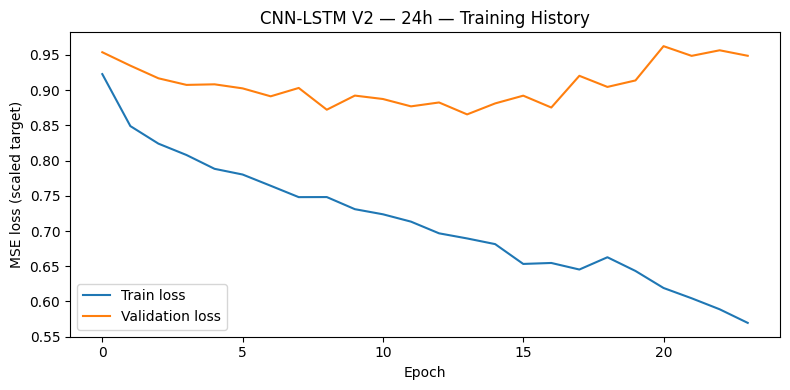


TEST RESULTS


,Horizon_hours,Model,MAE,RMSE,R2,sMAPE_percent,Parameters,Training_seconds,Best_epoch,Best_val_loss_scaled
0,24,CNN-LSTM-V2,66.957,99.315,0.1851,63.317,128833,802.8,14.0,0.865549
1,24,Persistence,83.233,121.450,-0.2186,76.683,0,0.0,NaN,NaN


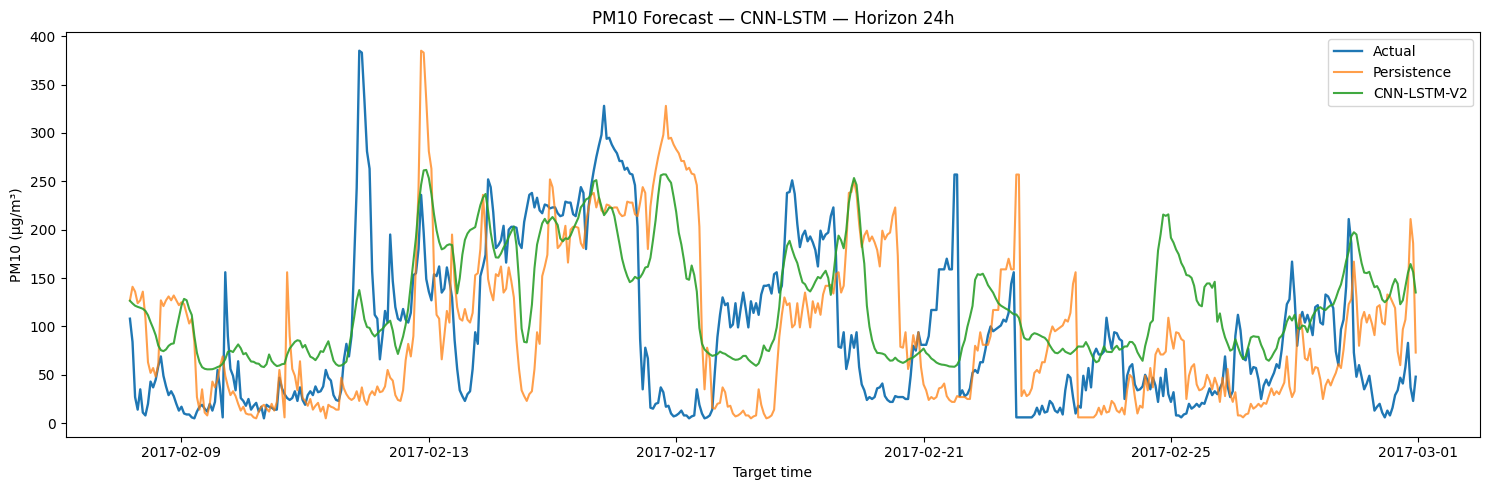

,datetime,actual_PM10,persistence,CNN_LSTM_V2
0,2016-07-24 20:00:00,93.000000,209.000001,118.251579
1,2016-07-24 21:00:00,83.000000,140.999999,116.924110
2,2016-07-24 22:00:00,53.000000,37.000000,109.522331
3,2016-07-24 23:00:00,107.000000,42.000001,104.207832
4,2016-07-25 00:00:00,107.000000,68.000000,99.002922
5,2016-07-25 01:00:00,93.000000,40.000003,97.080582
6,2016-07-25 02:00:00,128.000000,79.000001,95.191284
7,2016-07-25 03:00:00,93.000000,106.999999,93.023682
8,2016-07-25 04:00:00,56.999996,53.000002,87.512192
9,2016-07-25 05:00:00,56.000000,46.000003,83.367195


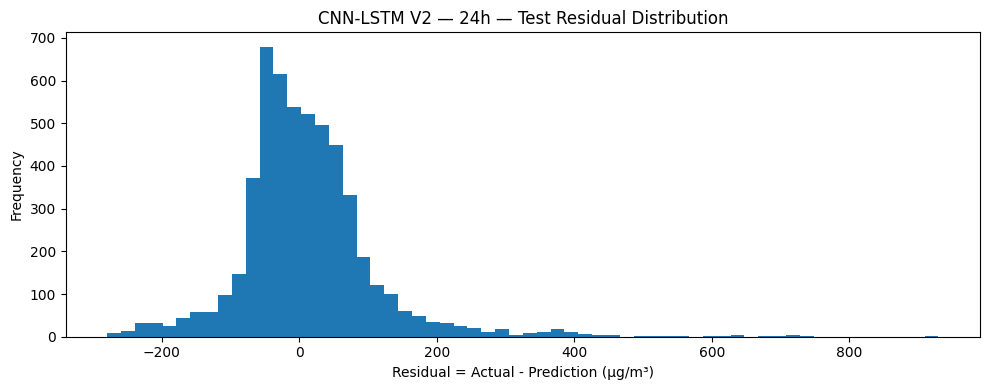

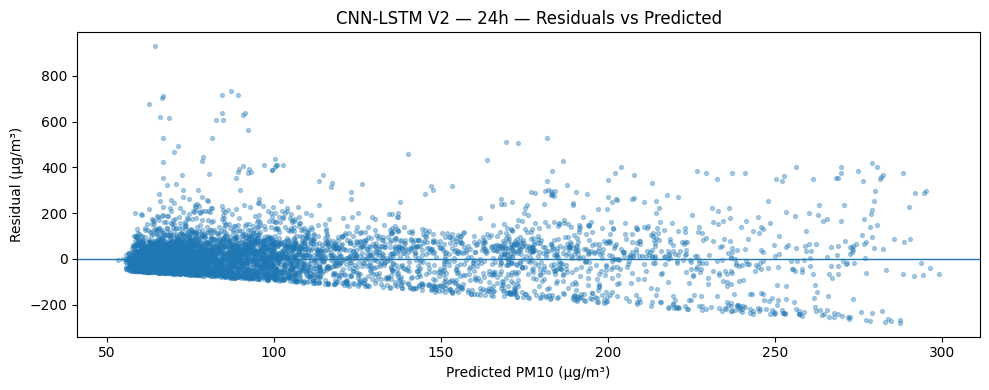


PEAK-POLLUTION RESULTS (top 10% of actual Test PM10)


,Horizon_hours,Model,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent
0,24,Persistence,246.0,535,172.336,216.345,-1.968,63.262
1,24,CNN-LSTM-V2,246.0,535,192.592,235.611,-2.520,71.380


In [19]:
result_24h = run_cnn_lstm_experiment(horizon=24)


# 16. مصورسازی کامل نتایج افق 24 ساعت

> **مهم:** از این بخش به بعد فقط مصورسازی و تحلیل نتایج انجام می‌شود.  
> هیچ تغییری در معماری، آموزش، وزن‌ها، داده‌های ورودی، preprocessing، loss، optimizer یا prediction مدل ایجاد نمی‌شود.

این بخش با همان منطق فایل Peak-Aware طراحی شده است:
- رنگ ثابت برای مدل‌ها؛
- برچسب‌های انگلیسی؛
- ذخیره PNG با `dpi=300`؛
- نمایش **همان شکل داخل Notebook** با `plt.show()`؛
- تحلیل Overall و Peak به‌صورت جداگانه؛
- نمودارهای تشخیصی برای توضیح علت رفتار مدل در فصل نتایج.


In [20]:

import seaborn as sns
from pathlib import Path

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass

sns.set_theme(style="whitegrid")

FIG_DIR = OUTPUT_DIR / "results_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODEL_COLORS = {
    "Actual": "#111111",
    "Persistence": "#7f7f7f",
    "CNN-LSTM-V2": "#9467bd",
    "GRU": "#2ca02c",
}

DISPLAY_NAMES = {
    "Persistence": "Persistence",
    "CNN-LSTM-V2": "CNN-LSTM",
    "GRU": "GRU",
}

FIGURE_MANIFEST = []

def save_figure(filename):
    """Save at thesis quality and ALSO display inline in the notebook."""
    path = FIG_DIR / filename
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)
    FIGURE_MANIFEST.append(str(path))
    plt.show()
    plt.close()

# -----------------------------
# Common 24h objects
# -----------------------------
comparison_24h = result_24h["comparison"].copy()
peak_24h = result_24h["peak_comparison"].copy()

y_test = np.asarray(result_24h["y_test_real"], dtype=float)
pred_persistence = np.asarray(result_24h["persistence_test"], dtype=float)
pred_cnn = np.asarray(result_24h["pred_real"], dtype=float)
test_time = result_24h["data"]["time_test"]

history_df = pd.DataFrame(result_24h["history"].history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))

MODEL_PREDICTIONS = {
    "Persistence": pred_persistence,
    "CNN-LSTM-V2": pred_cnn,
}

ordered_models = ["Persistence", "CNN-LSTM-V2"]

# Test benchmark peaks = actual test top 10%
test_top10_threshold = float(np.quantile(y_test, 0.90))
test_peak_mask = y_test >= test_top10_threshold

# Train-only P90 shown as an operational/reference threshold
y_train_scaled = np.asarray(result_24h["data"]["y_train"], dtype=float).reshape(-1, 1)
y_train_real = target_scaler.inverse_transform(y_train_scaled).ravel()
train_p90_threshold = float(np.quantile(y_train_real, 0.90))

overall_lookup = comparison_24h.set_index("Model")
peak_lookup = peak_24h.set_index("Model")

print("Train-only P90 threshold:", round(train_p90_threshold, 3))
print("Test top-10% benchmark threshold:", round(test_top10_threshold, 3))
display(comparison_24h.round({
    "MAE": 3, "RMSE": 3, "R2": 4,
    "sMAPE_percent": 3, "Training_seconds": 1
}))
display(peak_24h.round(3))


Train-only P90 threshold: 243.0
Test top-10% benchmark threshold: 246.0


,Horizon_hours,Model,MAE,RMSE,R2,sMAPE_percent,Parameters,Training_seconds,Best_epoch,Best_val_loss_scaled
0,24,CNN-LSTM-V2,66.957,99.315,0.1851,63.317,128833,802.8,14.0,0.865549
1,24,Persistence,83.233,121.450,-0.2186,76.683,0,0.0,NaN,NaN


,Horizon_hours,Model,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent
0,24,Persistence,246.0,535,172.336,216.345,-1.968,63.262
1,24,CNN-LSTM-V2,246.0,535,192.592,235.611,-2.520,71.380


## 16.1 Training history

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_training_history.png


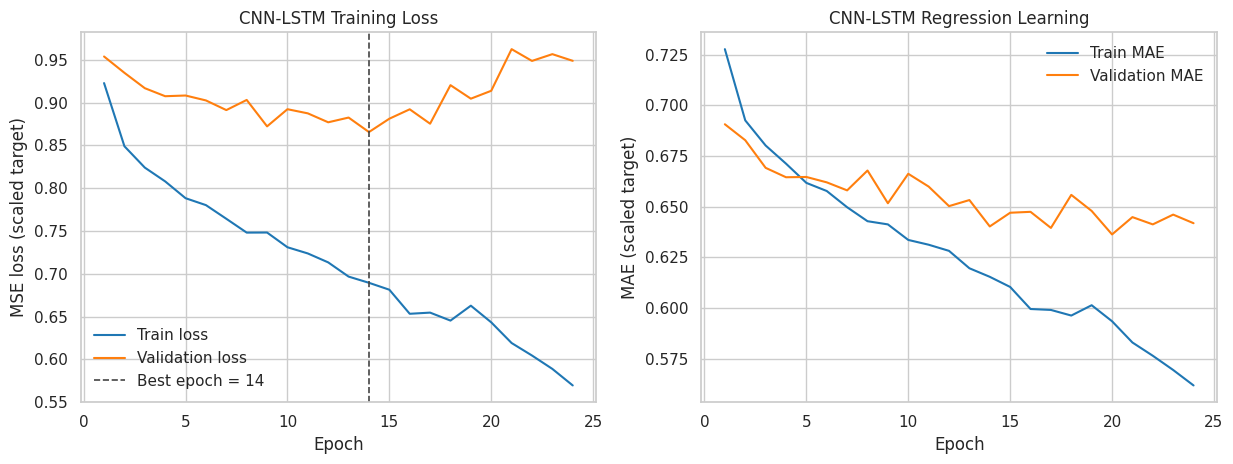

In [21]:

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

epochs = history_df["epoch"].to_numpy()
best_epoch = int(np.argmin(history_df["val_loss"].to_numpy()) + 1)

axes[0].plot(
    epochs, history_df["loss"],
    label="Train loss", color="#1f77b4"
)
axes[0].plot(
    epochs, history_df["val_loss"],
    label="Validation loss", color="#ff7f0e"
)
axes[0].axvline(
    best_epoch,
    linestyle="--",
    linewidth=1.2,
    color="#444444",
    label=f"Best epoch = {best_epoch}"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss (scaled target)")
axes[0].set_title("CNN-LSTM Training Loss")
axes[0].legend()

mae_key = "mae" if "mae" in history_df.columns else None
val_mae_key = "val_mae" if "val_mae" in history_df.columns else None

if mae_key and val_mae_key:
    axes[1].plot(
        epochs, history_df[mae_key],
        label="Train MAE", color="#1f77b4"
    )
    axes[1].plot(
        epochs, history_df[val_mae_key],
        label="Validation MAE", color="#ff7f0e"
    )
    axes[1].set_ylabel("MAE (scaled target)")
    axes[1].set_title("CNN-LSTM Regression Learning")
    axes[1].legend()
else:
    axes[1].plot(
        epochs,
        history_df["val_loss"] - history_df["loss"],
        color="#9467bd"
    )
    axes[1].axhline(0, color="#333333", linewidth=1)
    axes[1].set_ylabel("Validation loss - Train loss")
    axes[1].set_title("Generalization Gap")

axes[1].set_xlabel("Epoch")

plt.tight_layout()
save_figure("h24_training_history.png")


## 16.2 Actual vs Predicted

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_actual_vs_predicted_grid.png


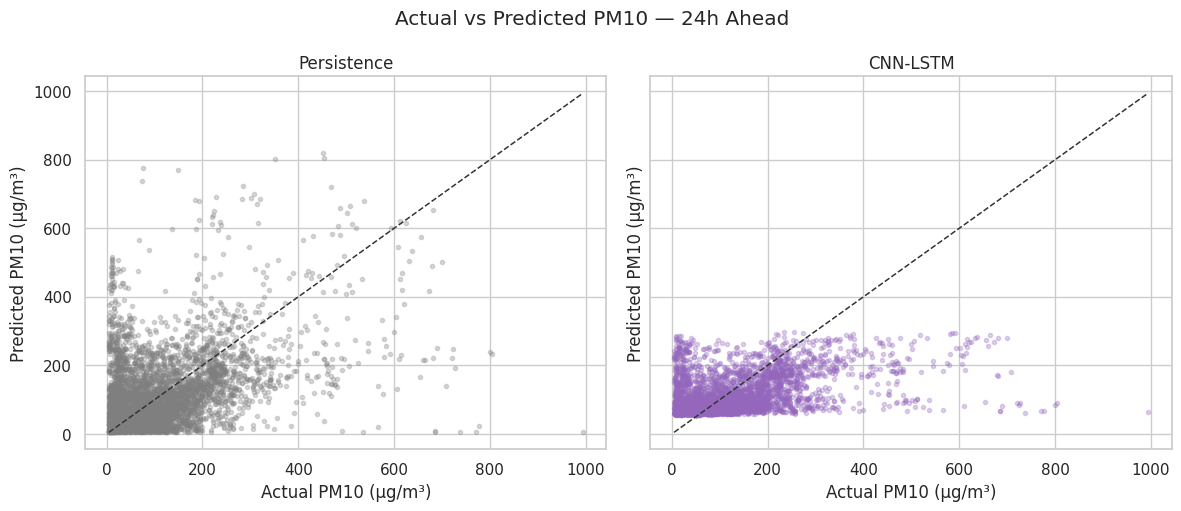

In [22]:

max_points = 4500

if len(y_test) > max_points:
    idx = np.linspace(0, len(y_test)-1, max_points).astype(int)
else:
    idx = np.arange(len(y_test))

lo = float(min(
    y_test.min(),
    pred_persistence.min(),
    pred_cnn.min()
))
hi = float(max(
    y_test.max(),
    pred_persistence.max(),
    pred_cnn.max()
))

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.2),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(axes, ordered_models):
    pred = MODEL_PREDICTIONS[model_name]

    ax.scatter(
        y_test[idx],
        pred[idx],
        s=9,
        alpha=0.30,
        color=MODEL_COLORS[model_name]
    )

    ax.plot(
        [lo, hi], [lo, hi],
        "--",
        linewidth=1.1,
        color="#333333"
    )

    ax.set_title(DISPLAY_NAMES[model_name])
    ax.set_xlabel("Actual PM10 (µg/m³)")
    ax.set_ylabel("Predicted PM10 (µg/m³)")

fig.suptitle("Actual vs Predicted PM10 — 24h Ahead")
plt.tight_layout()
save_figure("h24_actual_vs_predicted_grid.png")


## 16.3 Peak-centered forecast overlay

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_peak_centered_overlay.png


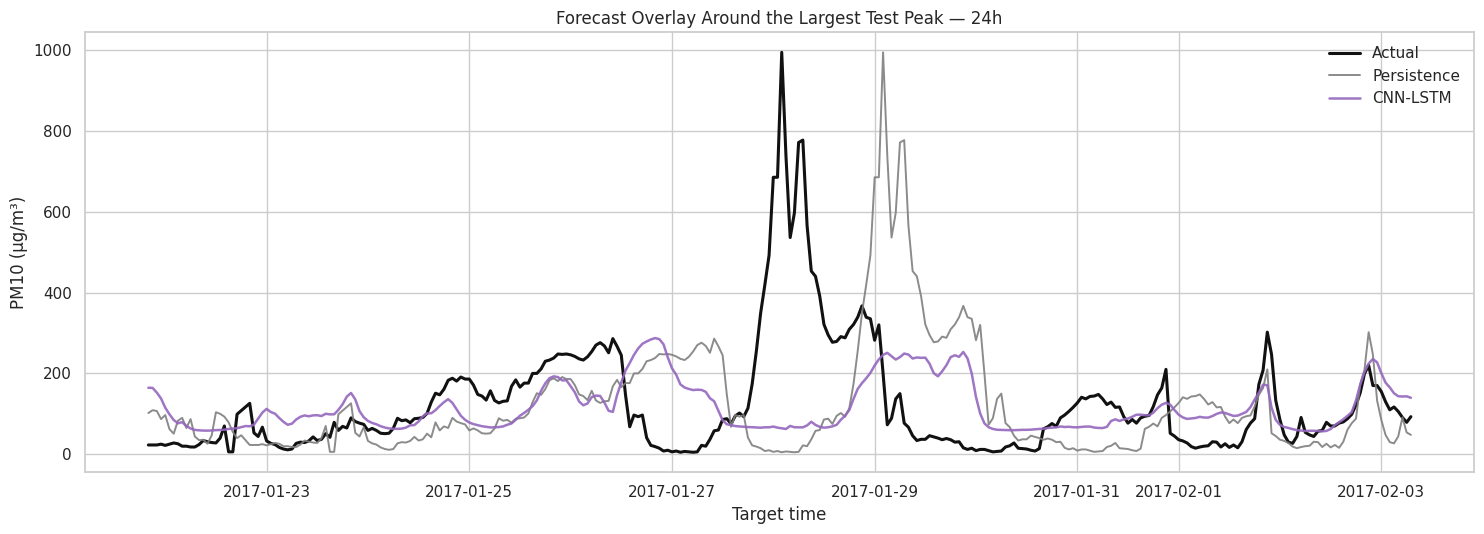

In [23]:

WINDOW = 300
center_idx = int(np.argmax(y_test))

start = max(0, center_idx - WINDOW//2)
end = min(len(y_test), start + WINDOW)
start = max(0, end - WINDOW)

sl = slice(start, end)

plt.figure(figsize=(15, 5.5))

plt.plot(
    test_time[sl],
    y_test[sl],
    linewidth=2.2,
    label="Actual",
    color=MODEL_COLORS["Actual"]
)

for model_name in ordered_models:
    plt.plot(
        test_time[sl],
        MODEL_PREDICTIONS[model_name][sl],
        linewidth=1.4 if model_name == "Persistence" else 1.8,
        alpha=0.90,
        label=DISPLAY_NAMES[model_name],
        color=MODEL_COLORS[model_name]
    )

plt.xlabel("Target time")
plt.ylabel("PM10 (µg/m³)")
plt.title("Forecast Overlay Around the Largest Test Peak — 24h")
plt.legend()
plt.tight_layout()
save_figure("h24_peak_centered_overlay.png")


## 16.4 Overall vs Peak RMSE

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/overall_vs_peak_rmse_bar.png


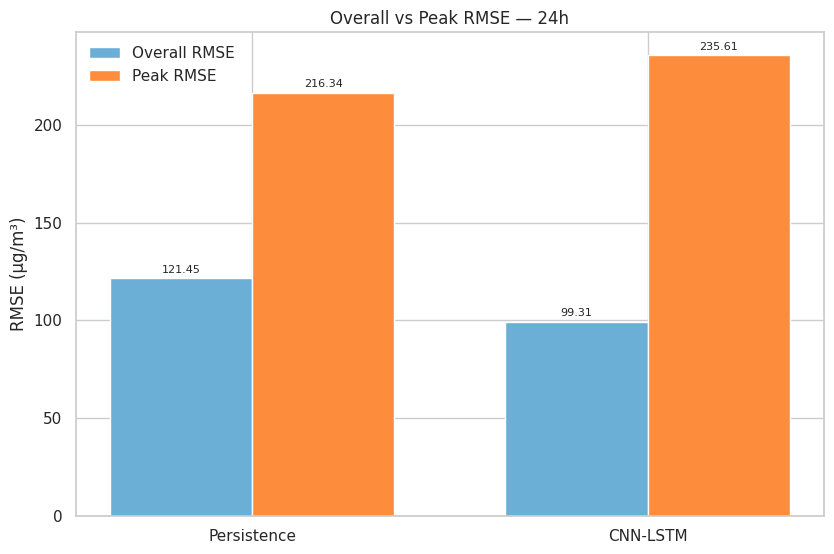

In [24]:

bar_df = (
    comparison_24h[["Model", "RMSE"]]
    .rename(columns={"RMSE": "Overall_RMSE"})
    .merge(
        peak_24h[["Model", "RMSE"]]
        .rename(columns={"RMSE": "Peak_RMSE"}),
        on="Model",
        how="inner"
    )
)

bar_df["order"] = bar_df["Model"].map({
    "Persistence": 0,
    "CNN-LSTM-V2": 1
})
bar_df = bar_df.sort_values("order")

x = np.arange(len(bar_df))
width = 0.36

plt.figure(figsize=(8.5, 5.7))

b1 = plt.bar(
    x-width/2,
    bar_df["Overall_RMSE"],
    width,
    label="Overall RMSE",
    color="#6baed6"
)
b2 = plt.bar(
    x+width/2,
    bar_df["Peak_RMSE"],
    width,
    label="Peak RMSE",
    color="#fd8d3c"
)

plt.xticks(
    x,
    [DISPLAY_NAMES[m] for m in bar_df["Model"]]
)
plt.ylabel("RMSE (µg/m³)")
plt.title("Overall vs Peak RMSE — 24h")
plt.legend()

for bars in [b1, b2]:
    for b in bars:
        v = b.get_height()
        plt.annotate(
            f"{v:.2f}",
            (b.get_x()+b.get_width()/2, v),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

plt.tight_layout()
save_figure("overall_vs_peak_rmse_bar.png")


## 16.5 Overall metrics comparison grid

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_all_metrics_comparison_grid.png


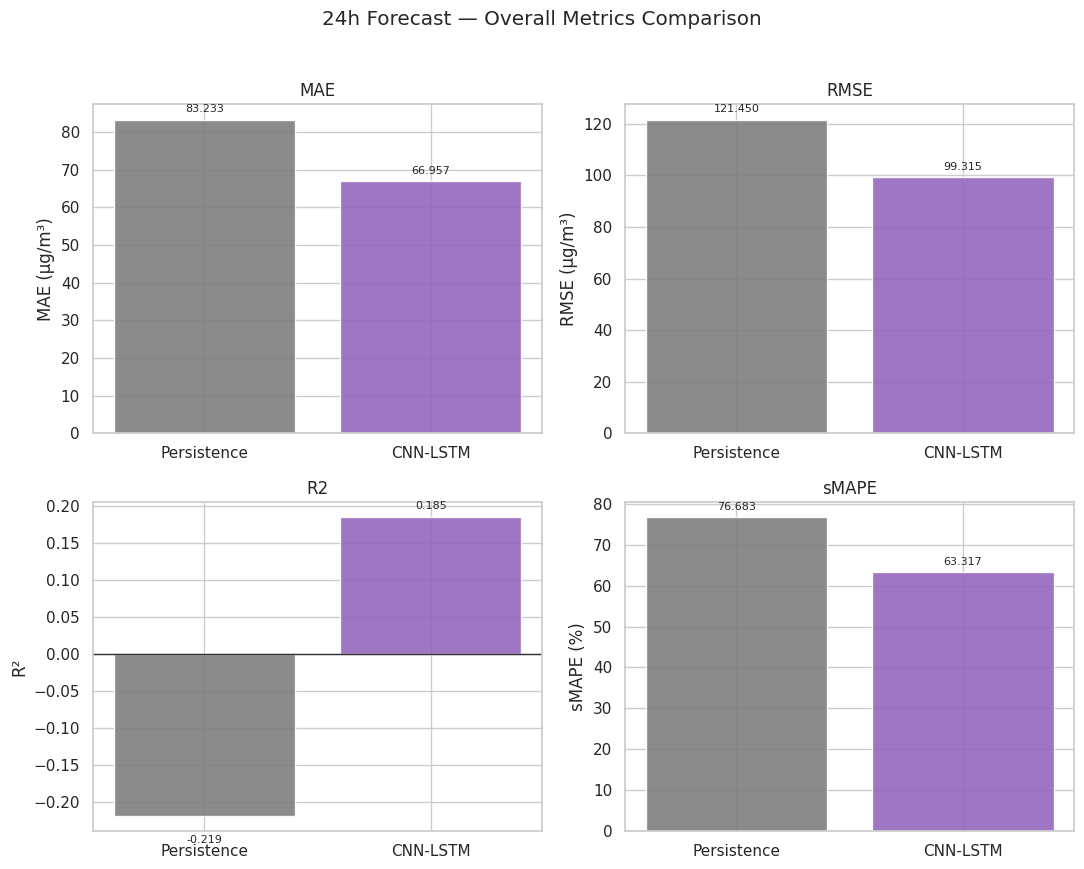

In [25]:

metric_specs = [
    ("MAE", "MAE (µg/m³)"),
    ("RMSE", "RMSE (µg/m³)"),
    ("R2", "R²"),
    ("sMAPE_percent", "sMAPE (%)"),
]

plot_df = (
    comparison_24h
    .set_index("Model")
    .loc[ordered_models]
    .reset_index()
)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
axes = axes.ravel()

for ax, (metric, ylabel) in zip(axes, metric_specs):
    colors = [MODEL_COLORS[m] for m in plot_df["Model"]]

    bars = ax.bar(
        [DISPLAY_NAMES[m] for m in plot_df["Model"]],
        plot_df[metric],
        color=colors,
        alpha=0.90
    )

    ax.set_title(
        metric if metric != "sMAPE_percent" else "sMAPE"
    )
    ax.set_ylabel(ylabel)

    if metric == "R2":
        ax.axhline(0, color="#333333", linewidth=1.0)

    for bar, val in zip(bars, plot_df[metric]):
        ax.annotate(
            f"{val:.3f}",
            (bar.get_x() + bar.get_width()/2, bar.get_height()),
            xytext=(0, 4 if val >= 0 else -14),
            textcoords="offset points",
            ha="center",
            va="bottom" if val >= 0 else "top",
            fontsize=8
        )

fig.suptitle("24h Forecast — Overall Metrics Comparison", y=1.02)
plt.tight_layout()
save_figure("h24_all_metrics_comparison_grid.png")


## 16.6 Improvement over Persistence — Overall vs Peak

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_improvement_over_persistence_bar.png


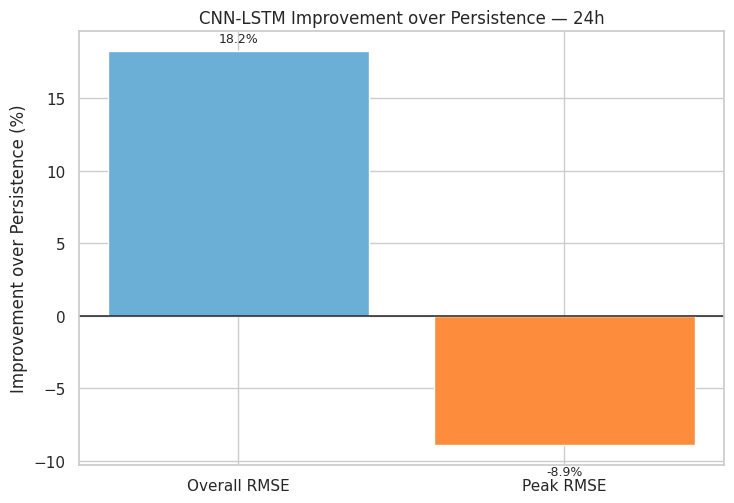

In [26]:

baseline_overall_rmse = float(
    overall_lookup.loc["Persistence", "RMSE"]
)
baseline_peak_rmse = float(
    peak_lookup.loc["Persistence", "RMSE"]
)

cnn_overall_rmse = float(
    overall_lookup.loc["CNN-LSTM-V2", "RMSE"]
)
cnn_peak_rmse = float(
    peak_lookup.loc["CNN-LSTM-V2", "RMSE"]
)

overall_improvement = 100.0 * (
    baseline_overall_rmse - cnn_overall_rmse
) / baseline_overall_rmse

peak_improvement = 100.0 * (
    baseline_peak_rmse - cnn_peak_rmse
) / baseline_peak_rmse

imp_df = pd.DataFrame({
    "Metric": ["Overall RMSE", "Peak RMSE"],
    "Improvement_pct": [
        overall_improvement,
        peak_improvement
    ]
})

plt.figure(figsize=(7.5, 5.2))
bars = plt.bar(
    imp_df["Metric"],
    imp_df["Improvement_pct"],
    color=["#6baed6", "#fd8d3c"]
)

plt.axhline(0, color="#222222", linewidth=1.1)
plt.ylabel("Improvement over Persistence (%)")
plt.title("CNN-LSTM Improvement over Persistence — 24h")

for bar in bars:
    h = bar.get_height()
    plt.annotate(
        f"{h:.1f}%",
        (bar.get_x()+bar.get_width()/2, h),
        xytext=(0, 4 if h >= 0 else -14),
        textcoords="offset points",
        ha="center",
        va="bottom" if h >= 0 else "top",
        fontsize=9
    )

plt.tight_layout()
save_figure("h24_improvement_over_persistence_bar.png")


## 16.7 Residual diagnostics

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_residuals_grid.png


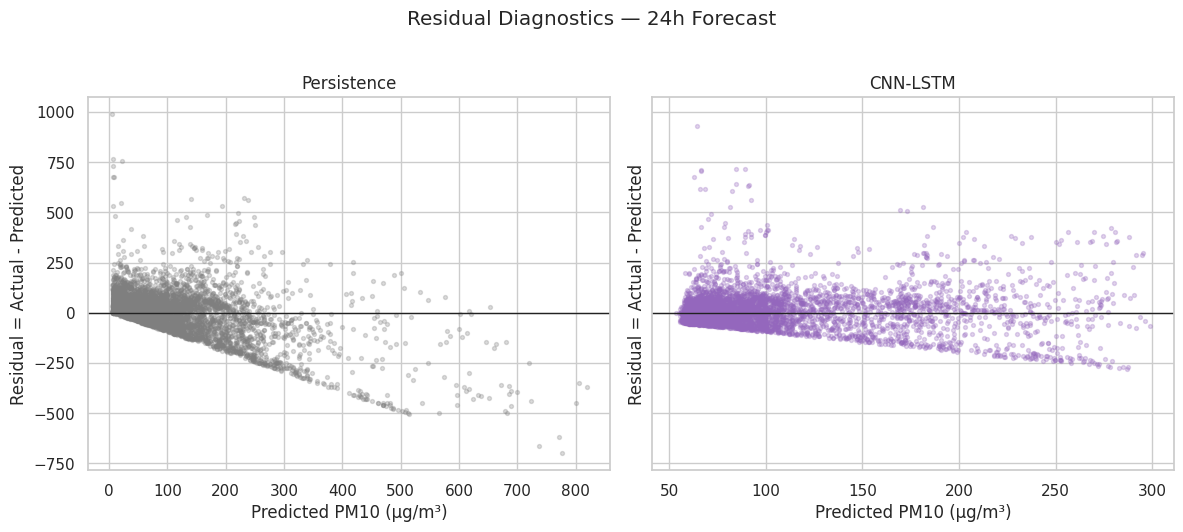

In [27]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.2),
    sharey=True
)

for ax, model_name in zip(axes, ordered_models):
    pred = MODEL_PREDICTIONS[model_name]
    residual = y_test - pred

    idx = np.arange(len(y_test))
    if len(idx) > 4500:
        idx = np.linspace(
            0, len(idx)-1, 4500
        ).astype(int)

    ax.scatter(
        pred[idx],
        residual[idx],
        s=8,
        alpha=0.28,
        color=MODEL_COLORS[model_name]
    )
    ax.axhline(
        0,
        color="#222222",
        linewidth=1.0
    )
    ax.set_title(DISPLAY_NAMES[model_name])
    ax.set_xlabel("Predicted PM10 (µg/m³)")
    ax.set_ylabel("Residual = Actual - Predicted")

fig.suptitle("Residual Diagnostics — 24h Forecast", y=1.02)
plt.tight_layout()
save_figure("h24_residuals_grid.png")


## 16.8 Residual distributions

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_residual_distribution_grid.png


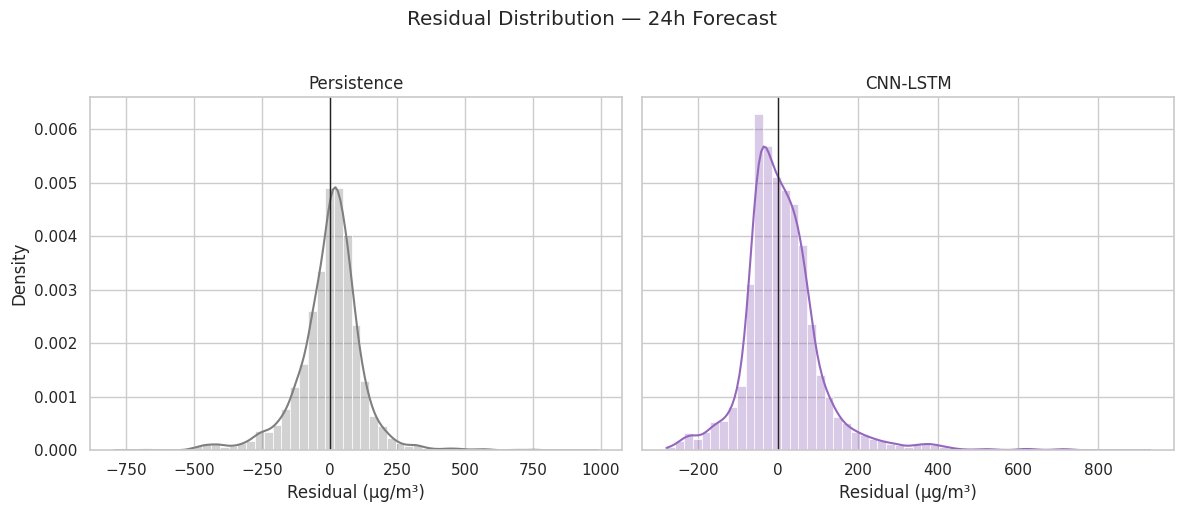

In [28]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.0),
    sharey=True
)

for ax, model_name in zip(axes, ordered_models):
    residual = (
        y_test - MODEL_PREDICTIONS[model_name]
    )

    sns.histplot(
        residual,
        bins=55,
        stat="density",
        kde=True,
        color=MODEL_COLORS[model_name],
        alpha=0.35,
        ax=ax
    )

    ax.axvline(
        0,
        color="#222222",
        linewidth=1.0
    )
    ax.set_title(DISPLAY_NAMES[model_name])
    ax.set_xlabel("Residual (µg/m³)")
    ax.set_ylabel("Density")

fig.suptitle("Residual Distribution — 24h Forecast", y=1.02)
plt.tight_layout()
save_figure("h24_residual_distribution_grid.png")


## 16.9 PM10 distribution and peak thresholds

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/pm10_distribution_with_peak_threshold.png


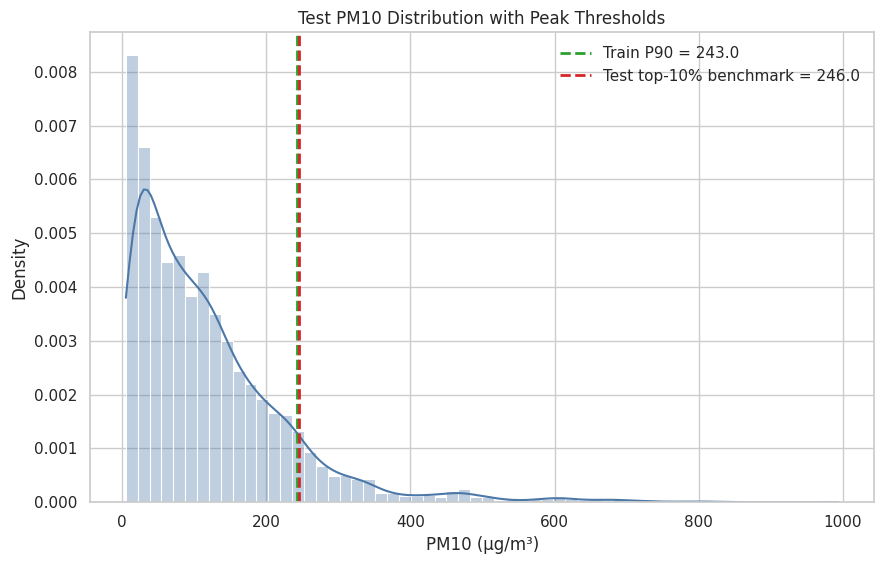

In [29]:

plt.figure(figsize=(9, 5.8))

sns.histplot(
    y_test,
    bins=60,
    stat="density",
    kde=True,
    color="#4c78a8",
    alpha=0.35
)

plt.axvline(
    train_p90_threshold,
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label=f"Train P90 = {train_p90_threshold:.1f}"
)

plt.axvline(
    test_top10_threshold,
    color="#d62728",
    linestyle="--",
    linewidth=2,
    label=f"Test top-10% benchmark = {test_top10_threshold:.1f}"
)

plt.xlabel("PM10 (µg/m³)")
plt.ylabel("Density")
plt.title("Test PM10 Distribution with Peak Thresholds")
plt.legend()
plt.tight_layout()
save_figure("pm10_distribution_with_peak_threshold.png")


## 16.10 Rank heatmap — Overall and Peak

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_rank_heatmap.png


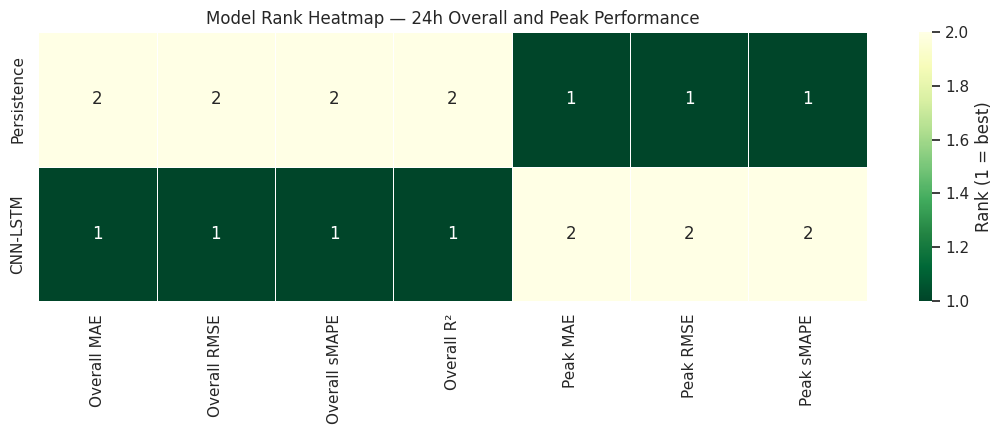

In [30]:

overall_rank = (
    comparison_24h
    .set_index("Model")[["MAE", "RMSE", "sMAPE_percent"]]
    .rank(method="min", ascending=True)
)

overall_r2_rank = (
    comparison_24h
    .set_index("Model")[["R2"]]
    .rank(method="min", ascending=False)
)

peak_rank = (
    peak_24h
    .set_index("Model")[["MAE", "RMSE", "sMAPE_percent"]]
    .rank(method="min", ascending=True)
)

rank_df = pd.concat([
    overall_rank.rename(columns={
        "MAE": "Overall MAE",
        "RMSE": "Overall RMSE",
        "sMAPE_percent": "Overall sMAPE"
    }),
    overall_r2_rank.rename(
        columns={"R2": "Overall R²"}
    ),
    peak_rank.rename(columns={
        "MAE": "Peak MAE",
        "RMSE": "Peak RMSE",
        "sMAPE_percent": "Peak sMAPE"
    })
], axis=1).loc[ordered_models]

rank_df.index = [
    DISPLAY_NAMES[i] for i in rank_df.index
]

plt.figure(figsize=(11, 4.5))

sns.heatmap(
    rank_df,
    annot=True,
    fmt=".0f",
    cmap="YlGn_r",
    cbar_kws={
        "label": "Rank (1 = best)"
    },
    linewidths=0.5
)

plt.title(
    "Model Rank Heatmap — 24h Overall and Peak Performance"
)
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
save_figure("h24_rank_heatmap.png")


## 16.11 Efficiency scatter — Training time vs RMSE

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_efficiency_scatter.png


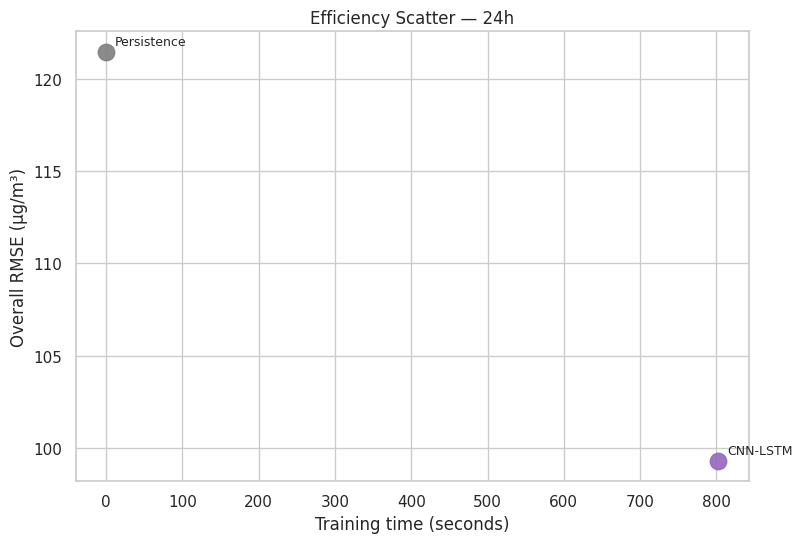

In [31]:

plt.figure(figsize=(8.2, 5.6))

for _, row in comparison_24h.iterrows():
    model_name = row["Model"]

    plt.scatter(
        row["Training_seconds"],
        row["RMSE"],
        s=140,
        color=MODEL_COLORS[model_name],
        alpha=0.9
    )

    plt.annotate(
        DISPLAY_NAMES[model_name],
        (
            row["Training_seconds"],
            row["RMSE"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Training time (seconds)")
plt.ylabel("Overall RMSE (µg/m³)")
plt.title("Efficiency Scatter — 24h")
plt.tight_layout()
save_figure("h24_efficiency_scatter.png")


## 16.12 Peak Actual vs Predicted

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_peak_actual_vs_predicted.png


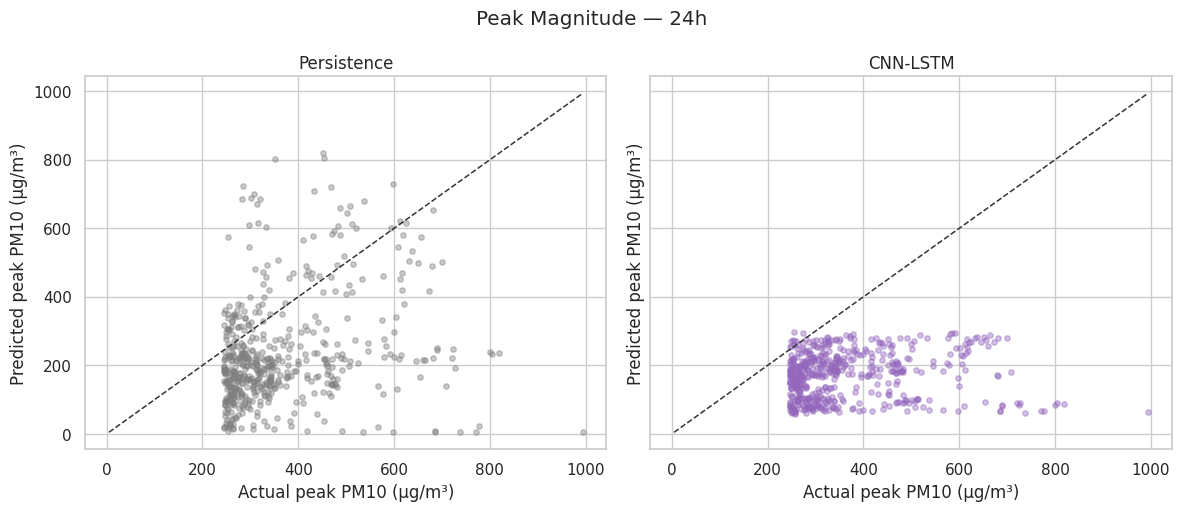

In [32]:

peak_actual = y_test[test_peak_mask]

peak_lo = float(min(
    peak_actual.min(),
    pred_persistence[test_peak_mask].min(),
    pred_cnn[test_peak_mask].min()
))

peak_hi = float(max(
    peak_actual.max(),
    pred_persistence[test_peak_mask].max(),
    pred_cnn[test_peak_mask].max()
))

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.2),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(axes, ordered_models):
    pred_peak = (
        MODEL_PREDICTIONS[model_name][test_peak_mask]
    )

    ax.scatter(
        peak_actual,
        pred_peak,
        s=15,
        alpha=0.42,
        color=MODEL_COLORS[model_name]
    )

    ax.plot(
        [peak_lo, peak_hi],
        [peak_lo, peak_hi],
        "--",
        linewidth=1.1,
        color="#333333"
    )

    ax.set_title(DISPLAY_NAMES[model_name])
    ax.set_xlabel("Actual peak PM10 (µg/m³)")
    ax.set_ylabel("Predicted peak PM10 (µg/m³)")

fig.suptitle("Peak Magnitude — 24h")
plt.tight_layout()
save_figure("h24_peak_actual_vs_predicted.png")


## 16.13 Peak magnitude capture ratios

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_peak_capture_ratio_bar.png


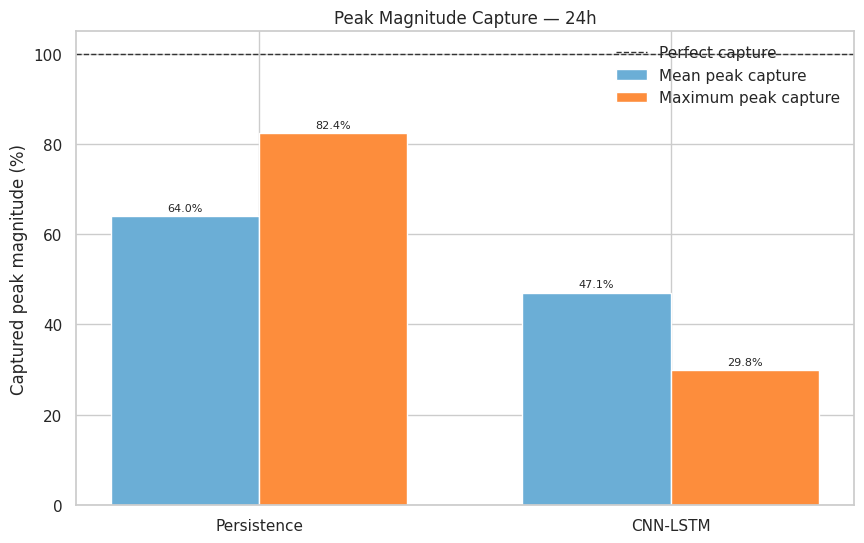

In [33]:

capture_rows = []

for model_name in ordered_models:
    pred_peak = (
        MODEL_PREDICTIONS[model_name][test_peak_mask]
    )

    capture_rows.append({
        "Model": model_name,
        "Mean_peak_capture_ratio":
            float(np.mean(pred_peak) / np.mean(peak_actual)),
        "Max_peak_capture_ratio":
            float(np.max(pred_peak) / np.max(peak_actual))
    })

capture_df = pd.DataFrame(capture_rows)

x = np.arange(len(capture_df))
width = 0.36

plt.figure(figsize=(8.8, 5.6))

bars1 = plt.bar(
    x-width/2,
    100*capture_df["Mean_peak_capture_ratio"],
    width,
    label="Mean peak capture",
    color="#6baed6"
)

bars2 = plt.bar(
    x+width/2,
    100*capture_df["Max_peak_capture_ratio"],
    width,
    label="Maximum peak capture",
    color="#fd8d3c"
)

plt.xticks(
    x,
    [DISPLAY_NAMES[m] for m in capture_df["Model"]]
)

plt.ylabel("Captured peak magnitude (%)")
plt.title("Peak Magnitude Capture — 24h")
plt.axhline(
    100,
    color="#333333",
    linestyle="--",
    linewidth=1.0,
    label="Perfect capture"
)
plt.legend()

for bars in [bars1, bars2]:
    for b in bars:
        v = b.get_height()
        plt.annotate(
            f"{v:.1f}%",
            (b.get_x()+b.get_width()/2, v),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

plt.tight_layout()
save_figure("h24_peak_capture_ratio_bar.png")


## 16.14 Error progression across PM10 deciles

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_mae_by_pm10_decile.png


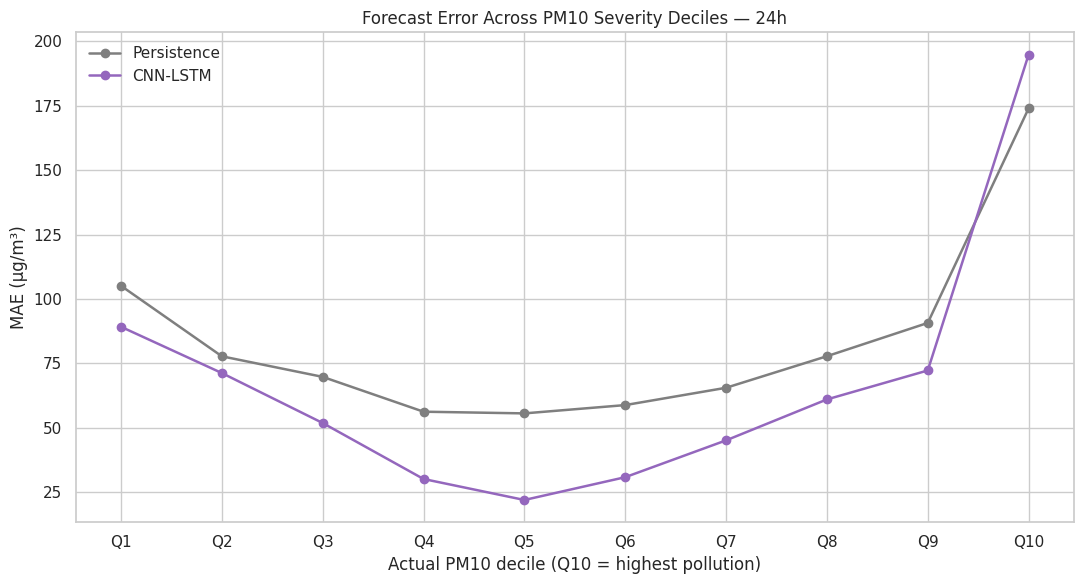

In [34]:

quantile_labels = [
    f"Q{i}" for i in range(1, 11)
]

quantile_bins = pd.qcut(
    pd.Series(y_test),
    q=10,
    labels=quantile_labels,
    duplicates="drop"
)

quantile_rows = []

for q in pd.Series(
    quantile_bins
).dropna().unique():

    mask = (
        quantile_bins == q
    ).to_numpy()

    for model_name in ordered_models:
        quantile_rows.append({
            "PM10_decile": str(q),
            "Model": model_name,
            "MAE": mean_absolute_error(
                y_test[mask],
                MODEL_PREDICTIONS[model_name][mask]
            )
        })

quantile_error_df = pd.DataFrame(
    quantile_rows
)

quantile_error_df["order"] = (
    quantile_error_df["PM10_decile"]
    .str.extract(r"(\d+)")
    .astype(int)
)

quantile_error_df = (
    quantile_error_df
    .sort_values(["order", "Model"])
)

plt.figure(figsize=(11, 6))

for model_name in ordered_models:
    d = (
        quantile_error_df[
            quantile_error_df["Model"]
            == model_name
        ]
        .sort_values("order")
    )

    plt.plot(
        d["PM10_decile"],
        d["MAE"],
        marker="o",
        linewidth=1.8,
        label=DISPLAY_NAMES[model_name],
        color=MODEL_COLORS[model_name]
    )

plt.xlabel(
    "Actual PM10 decile (Q10 = highest pollution)"
)
plt.ylabel("MAE (µg/m³)")
plt.title(
    "Forecast Error Across PM10 Severity Deciles — 24h"
)
plt.legend()
plt.tight_layout()
save_figure("h24_mae_by_pm10_decile.png")


## 16.15 Signed bias across PM10 deciles

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_bias_by_pm10_decile.png


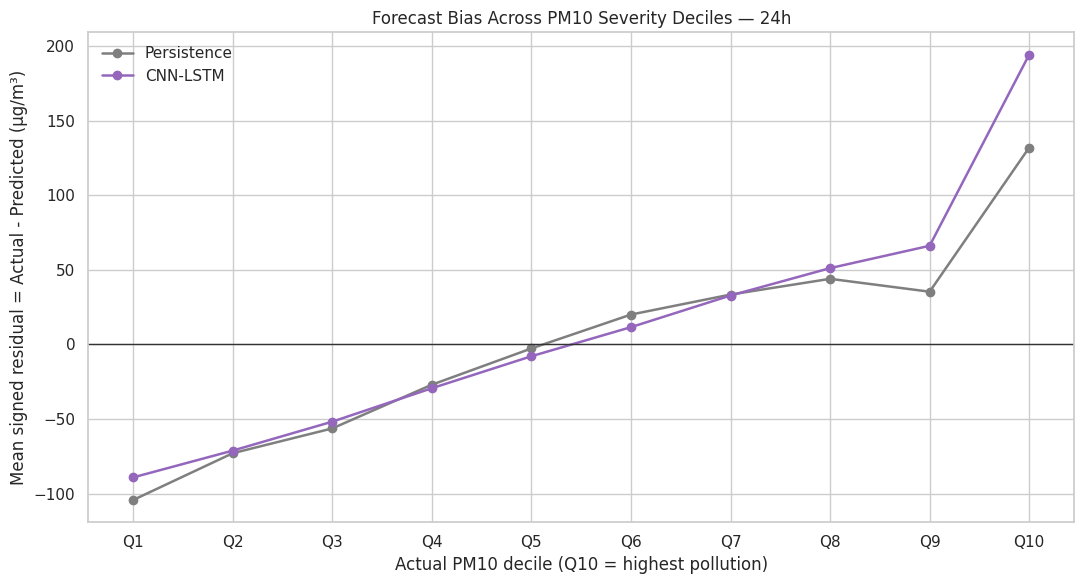

In [35]:

bias_rows = []

for q in pd.Series(
    quantile_bins
).dropna().unique():

    mask = (
        quantile_bins == q
    ).to_numpy()

    for model_name in ordered_models:
        residual = (
            y_test[mask]
            - MODEL_PREDICTIONS[model_name][mask]
        )

        bias_rows.append({
            "PM10_decile": str(q),
            "Model": model_name,
            "Mean_signed_residual": float(
                np.mean(residual)
            )
        })

bias_df = pd.DataFrame(bias_rows)

bias_df["order"] = (
    bias_df["PM10_decile"]
    .str.extract(r"(\d+)")
    .astype(int)
)

bias_df = (
    bias_df
    .sort_values(["order", "Model"])
)

plt.figure(figsize=(11, 6))

for model_name in ordered_models:
    d = (
        bias_df[
            bias_df["Model"] == model_name
        ]
        .sort_values("order")
    )

    plt.plot(
        d["PM10_decile"],
        d["Mean_signed_residual"],
        marker="o",
        linewidth=1.8,
        label=DISPLAY_NAMES[model_name],
        color=MODEL_COLORS[model_name]
    )

plt.axhline(
    0,
    color="#333333",
    linewidth=1.0
)

plt.xlabel(
    "Actual PM10 decile (Q10 = highest pollution)"
)
plt.ylabel(
    "Mean signed residual = Actual - Predicted (µg/m³)"
)
plt.title(
    "Forecast Bias Across PM10 Severity Deciles — 24h"
)
plt.legend()
plt.tight_layout()
save_figure("h24_bias_by_pm10_decile.png")


## 16.16 Absolute error vs Actual PM10

Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_absolute_error_vs_actual_grid.png


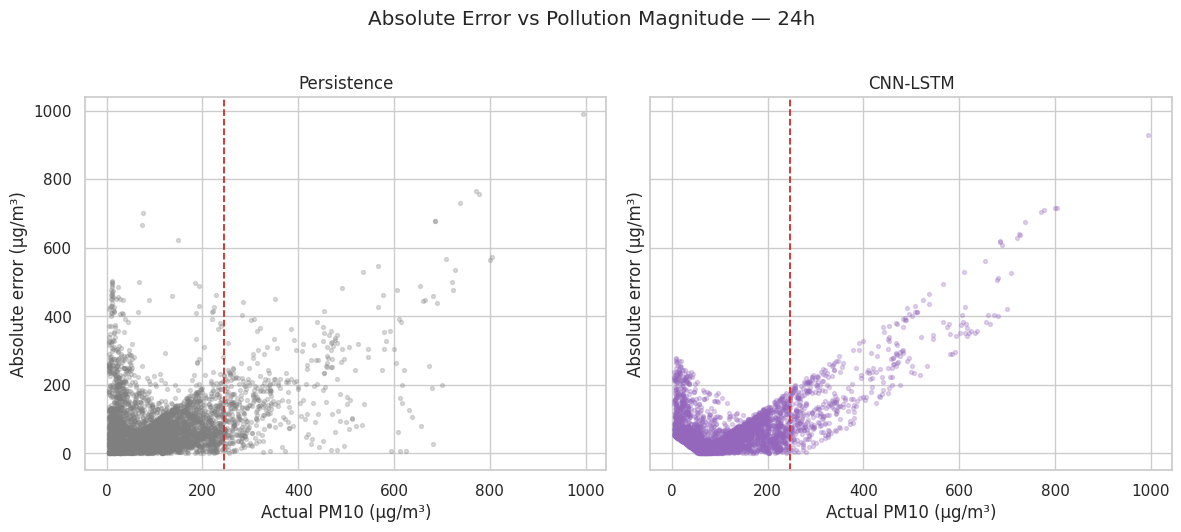

In [36]:

idx = np.arange(len(y_test))
if len(idx) > 4500:
    idx = np.linspace(
        0,
        len(idx)-1,
        4500
    ).astype(int)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.2),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(
    axes,
    ordered_models
):
    abs_error = np.abs(
        y_test - MODEL_PREDICTIONS[model_name]
    )

    ax.scatter(
        y_test[idx],
        abs_error[idx],
        s=8,
        alpha=0.28,
        color=MODEL_COLORS[model_name]
    )

    ax.axvline(
        test_top10_threshold,
        color="#d62728",
        linestyle="--",
        linewidth=1.3
    )

    ax.set_title(DISPLAY_NAMES[model_name])
    ax.set_xlabel("Actual PM10 (µg/m³)")
    ax.set_ylabel("Absolute error (µg/m³)")

fig.suptitle(
    "Absolute Error vs Pollution Magnitude — 24h",
    y=1.02
)
plt.tight_layout()
save_figure("h24_absolute_error_vs_actual_grid.png")


## 16.17 CNN-LSTM vs GRU reference

,Model,RMSE_24h
0,CNN-LSTM,99.315
1,GRU,99.781


Saved: outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures/h24_cnn_lstm_vs_gru_rmse.png


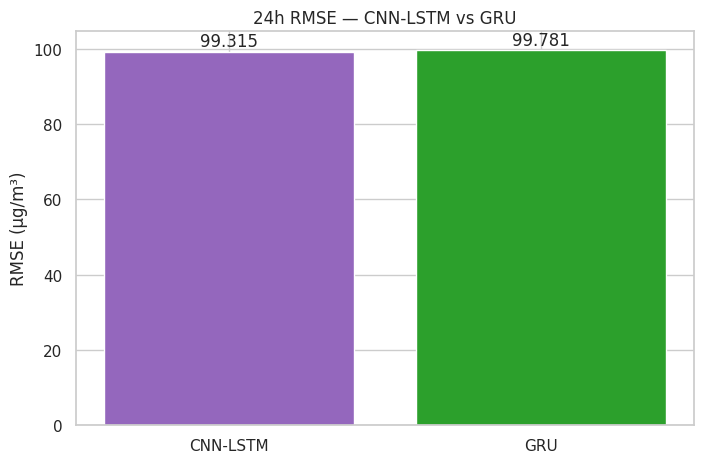

PASS: CNN-LSTM RMSE (99.315) is 0.466 lower than GRU (99.781).


In [37]:

# Read-only benchmark comparison.
# This number is NOT used for training, early stopping, tuning or model selection.
GRU_REFERENCE_RMSE_24H = 99.781

cnn_rmse_24h = float(
    overall_lookup.loc[
        "CNN-LSTM-V2",
        "RMSE"
    ]
)

gru_check_df = pd.DataFrame({
    "Model": [
        "CNN-LSTM",
        "GRU"
    ],
    "RMSE_24h": [
        cnn_rmse_24h,
        GRU_REFERENCE_RMSE_24H
    ]
})

display(gru_check_df.round(3))

plt.figure(figsize=(7.2, 4.8))

bars = plt.bar(
    gru_check_df["Model"],
    gru_check_df["RMSE_24h"],
    color=[
        MODEL_COLORS["CNN-LSTM-V2"],
        MODEL_COLORS["GRU"]
    ]
)

plt.ylabel("RMSE (µg/m³)")
plt.title("24h RMSE — CNN-LSTM vs GRU")

for bar, value in zip(
    bars,
    gru_check_df["RMSE_24h"]
):
    plt.annotate(
        f"{value:.3f}",
        (
            bar.get_x()+bar.get_width()/2,
            bar.get_height()
        ),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center"
    )

plt.tight_layout()
save_figure("h24_cnn_lstm_vs_gru_rmse.png")

delta = (
    cnn_rmse_24h
    - GRU_REFERENCE_RMSE_24H
)

if delta < 0:
    print(
        f"PASS: CNN-LSTM RMSE ({cnn_rmse_24h:.3f}) "
        f"is {abs(delta):.3f} lower than GRU "
        f"({GRU_REFERENCE_RMSE_24H:.3f})."
    )
else:
    print(
        f"NOTE: current CNN-LSTM run RMSE "
        f"({cnn_rmse_24h:.3f}) is {delta:.3f} "
        f"higher than GRU reference "
        f"({GRU_REFERENCE_RMSE_24H:.3f})."
    )


## 16.18 ذخیره خروجی‌های تحلیلی

In [38]:

# Save tables used in the figures
comparison_24h.to_csv(
    OUTPUT_DIR / "cnn_lstm_24h_test_metrics.csv",
    index=False
)

peak_24h.to_csv(
    OUTPUT_DIR / "cnn_lstm_24h_peak_metrics.csv",
    index=False
)

history_df.to_csv(
    OUTPUT_DIR / "cnn_lstm_24h_training_history.csv",
    index=False
)

capture_df.to_csv(
    OUTPUT_DIR / "cnn_lstm_24h_peak_capture.csv",
    index=False
)

quantile_error_df.to_csv(
    OUTPUT_DIR / "cnn_lstm_24h_mae_by_decile.csv",
    index=False
)

bias_df.to_csv(
    OUTPUT_DIR / "cnn_lstm_24h_bias_by_decile.csv",
    index=False
)

figure_manifest_df = pd.DataFrame({
    "figure_path": FIGURE_MANIFEST
})

figure_manifest_df.to_csv(
    OUTPUT_DIR / "figure_manifest.csv",
    index=False
)

joblib.dump(
    feature_scaler,
    OUTPUT_DIR / "feature_scaler.joblib"
)

joblib.dump(
    target_scaler,
    OUTPUT_DIR / "target_scaler.joblib"
)

print("Saved experiment outputs to:", OUTPUT_DIR.resolve())
print("Saved figures to:", FIG_DIR.resolve())

display(figure_manifest_df)


Saved experiment outputs to: /content/outputs_gucheng_cnn_lstm_v2_all_horizons
Saved figures to: /content/outputs_gucheng_cnn_lstm_v2_all_horizons/results_figures


,figure_path
0,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
1,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
2,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
3,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
4,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
5,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
6,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
7,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
8,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...
9,outputs_gucheng_cnn_lstm_v2_all_horizons/resul...



# 17. فهرست شکل‌های تولیدشده

پس از اجرای کامل Notebook، شکل‌های زیر هم **داخل Notebook نمایش داده می‌شوند** و هم در `results_figures/` ذخیره می‌شوند:

1. `h24_training_history.png`
2. `h24_actual_vs_predicted_grid.png`
3. `h24_peak_centered_overlay.png`
4. `overall_vs_peak_rmse_bar.png`
5. `h24_all_metrics_comparison_grid.png`
6. `h24_improvement_over_persistence_bar.png`
7. `h24_residuals_grid.png`
8. `h24_residual_distribution_grid.png`
9. `pm10_distribution_with_peak_threshold.png`
10. `h24_rank_heatmap.png`
11. `h24_efficiency_scatter.png`
12. `h24_peak_actual_vs_predicted.png`
13. `h24_peak_capture_ratio_bar.png`
14. `h24_mae_by_pm10_decile.png`
15. `h24_bias_by_pm10_decile.png`
16. `h24_absolute_error_vs_actual_grid.png`
17. `h24_cnn_lstm_vs_gru_rmse.png`

نمودارهای وابسته به **Gate، Peak-classification head، XGBoost residual corrector و calibration search** عمداً اضافه نشده‌اند، چون این اجزا متعلق به معماری Peak-Aware هستند و در CNN-LSTM وجود ندارند. به‌جای آن‌ها نمودارهای تشخیصی متناظر برای رفتار CNN-LSTM در شدت‌های مختلف PM10 اضافه شده است.
